# BÀI THỰC HÀNH 3.2: K-MEANS IMAGE SEGMENTATION
## NOTEBOOK 03: ELBOW METHOD, TÁI TẠO ẢNH VÀ SO SÁNH SIDE-BY-SIDE (TASK 4 & TASK 5)

Nội dung trọng tâm:
- Sử dụng Scikit-Learn `KMeans` với thuật toán khởi tạo tối ưu `k-means++`.
- Quét dải số cụm $K \in [2, 12]$ để vẽ đường cong quán tính WCSS theo phương pháp **Elbow Method**.
- Ứng dụng thuật toán hình học Kneedle để tự động xác định số cụm tối ưu $K_{\text{optimal}}$.
- **Task 4: Segment the Image**: Thay thế mỗi pixel bằng màu của tâm cụm tương ứng và reshape về kích thước 2D $(h, w, 3)$ cũng như phục hồi kích thước gốc $(H, W, 3)$.
- **Task 5: Visualize the Results**: Đặt ảnh gốc và ảnh phân đoạn cạnh nhau (Side-by-Side) để so sánh trực quan hiệu quả gom cụm màu sắc.

### 1. Nạp các thư viện và chuẩn bị ma trận điểm ảnh

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DEFAULT_IMAGE_PATH, TARGET_SIZE, K_SEARCH_RANGE, RANDOM_SEED, FIGURES_DIR, METRICS_DIR
from src.data.loader import load_image
from src.data.preprocessing import resize_image, flatten_pixels
from src.models.kmeans_sklearn import SklearnKMeansTrainer
from src.segmentation.segmenter import ImageSegmenter
from src.features.color_features import extract_color_distribution
from src.evaluation.visualization import plot_elbow_curve, plot_side_by_side, plot_cluster_distribution

# Đọc ảnh gốc và trích xuất ma trận pixel kích thước làm việc
img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
orig_shape = metadata["original_shape"]

img_resized, (h_resized, w_resized) = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(img_resized, as_float=True)

print(f"Ảnh gốc: {orig_shape} | Ảnh làm việc: ({h_resized}, {w_resized}) | Pixel matrix: {pixel_matrix.shape}")

2026-11-14 11:09:23 [INFO] DataLoader — Đọc ảnh bằng OpenCV: image-liquid.jpg
2026-11-14 11:09:23 [INFO] DataLoader — Ảnh đã nạp — image-liquid.jpg | 3264×3264×3 | 10,653,696 pixels | 2095.2 KB
2026-11-14 11:09:24 [INFO] Preprocessing — Resize ảnh: (3264x3264) -> (256x256) | scale=0.078
2026-11-14 11:09:24 [INFO] Preprocessing — Flatten pixels: (256x256x3) -> (65536, 3) | dtype=float32
Ảnh gốc: (3264, 3264, 3) | Ảnh làm việc: (256, 256) | Pixel matrix: (65536, 3)


### 2. Quét Elbow Method và tự động tìm K tối ưu (K=2..12)
Chạy K-Means với các giá trị $K$ từ 2 đến 12 để ghi nhận độ suy giảm quán tính WCSS.

2026-11-14 11:09:41 [INFO] SklearnKMeansTrainer — Bắt đầu quét Elbow | K ∈ [2, 12]
2026-11-14 11:09:41 [INFO] SklearnKMeansTrainer —   K= 2 | WCSS=334193408.00
2026-11-14 11:09:42 [INFO] SklearnKMeansTrainer —   K= 3 | WCSS=232993376.00
2026-11-14 11:09:42 [INFO] SklearnKMeansTrainer —   K= 4 | WCSS=156334560.00
2026-11-14 11:09:42 [INFO] SklearnKMeansTrainer —   K= 5 | WCSS=121024896.00
2026-11-14 11:09:43 [INFO] SklearnKMeansTrainer —   K= 6 | WCSS=104840560.00
2026-11-14 11:09:43 [INFO] SklearnKMeansTrainer —   K= 7 | WCSS=90721280.00
2026-11-14 11:09:44 [INFO] SklearnKMeansTrainer —   K= 8 | WCSS=78616712.00
2026-11-14 11:09:44 [INFO] SklearnKMeansTrainer —   K= 9 | WCSS=70459616.00
2026-11-14 11:09:45 [INFO] SklearnKMeansTrainer —   K=10 | WCSS=64330168.00
2026-11-14 11:09:46 [INFO] SklearnKMeansTrainer —   K=11 | WCSS=58793064.00
2026-11-14 11:09:47 [INFO] SklearnKMeansTrainer —   K=12 | WCSS=54090596.00
2026-11-14 11:09:47 [INFO] SklearnKMeansTrainer — [kneed] Elbow point: K=5
2

,K,Inertia
0,2,334193408.0
1,3,232993376.0
2,4,156334560.0
3,5,121024896.0
4,6,104840560.0
5,7,90721280.0
6,8,78616712.0
7,9,70459616.0
8,10,64330168.0
9,11,58793064.0



>>> Điểm khuỷu tay tối ưu được xác định tự động: K = 5
2026-11-14 11:09:48 [INFO] Visualization — Đã lưu elbow curve: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\results\figures\elbow_method_nb03.png


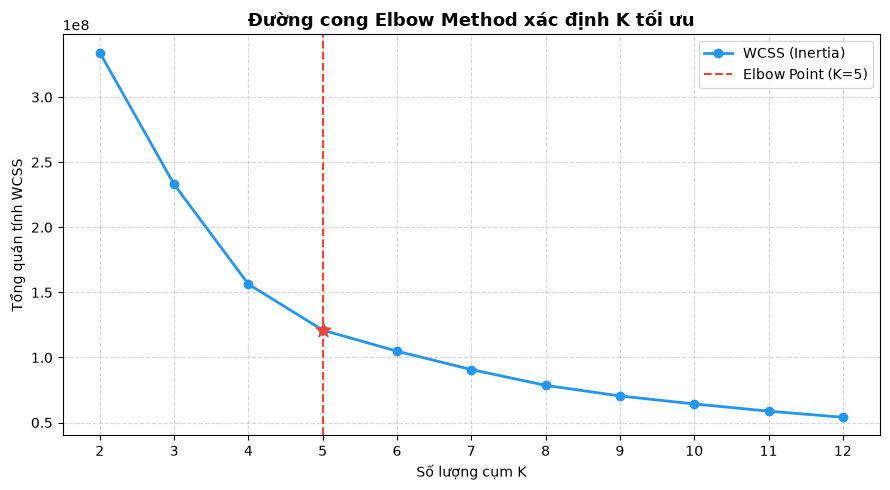

In [2]:
trainer = SklearnKMeansTrainer(random_state=RANDOM_SEED)
df_elbow, optimal_k = trainer.search_elbow(pixel_matrix, k_range=K_SEARCH_RANGE)

print("=== BẢNG SỐ LIỆU ELBOW METHOD ===")
display(df_elbow)

print(f"\n>>> Điểm khuỷu tay tối ưu được xác định tự động: K = {optimal_k}")

# Vẽ đường cong Elbow và lưu vào results/figures
plot_elbow_curve(df_elbow, optimal_k, save_path=FIGURES_DIR / "elbow_method_nb03.png")

# Hiển thị trực tiếp trong notebook
plt.figure(figsize=(9, 5))
plt.plot(df_elbow["K"], df_elbow["Inertia"], marker="o", linewidth=2, color="#2196F3", label="WCSS (Inertia)")
plt.axvline(x=optimal_k, color="#F44336", linestyle="--", label=f"Elbow Point (K={optimal_k})")
elbow_wcss = df_elbow.loc[df_elbow["K"] == optimal_k, "Inertia"].values[0]
plt.scatter([optimal_k], [elbow_wcss], color="#F44336", s=120, zorder=5, marker="*")
plt.title("Đường cong Elbow Method xác định K tối ưu", fontsize=13, fontweight="bold")
plt.xlabel("Số lượng cụm K")
plt.ylabel("Tổng quán tính WCSS")
plt.xticks(df_elbow["K"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Huấn luyện mô hình K-Means cuối cùng với K tối ưu
Sử dụng $K=K_{\text{optimal}}$ với 10 lần khởi tạo `k-means++` để đạt giải pháp tối ưu nhất.

In [3]:
final_model = trainer.fit_final_model(pixel_matrix, optimal_k=optimal_k)

labels = final_model.labels_
centroids = final_model.cluster_centers_

print(f"Huấn luyện thành công mô hình K-Means cuối cùng (K={optimal_k}):")
print(f"- WCSS đạt được: {final_model.inertia_:,.2f}")
print(f"- Số vòng lặp hội tụ: {final_model.n_iter_}")
print(f"- Hình dạng ma trận tâm cụm: {centroids.shape}")

2026-11-14 11:09:53 [INFO] SklearnKMeansTrainer — Huấn luyện mô hình cuối cùng | K=5 | n_init=10
2026-11-14 11:09:54 [INFO] SklearnKMeansTrainer — Mô hình cuối đã sẵn sàng | WCSS=121024896.00 | n_iter=7
Huấn luyện thành công mô hình K-Means cuối cùng (K=5):
- WCSS đạt được: 121,024,896.00
- Số vòng lặp hội tụ: 7
- Hình dạng ma trận tâm cụm: (5, 3)


### 4. Tái tạo ảnh phân đoạn và phục hồi độ phân giải gốc (Task 4)
Ánh xạ mỗi điểm ảnh sang màu tâm cụm và reshape mảng 1D $(N, 3)$ trở lại không gian 2D ảnh.

In [4]:
segmenter = ImageSegmenter()

# 1. Tái tạo ở kích thước làm việc (256x256)
segmented_resized = segmenter.reconstruct_segmented_image(
    labels=labels,
    centroids=centroids,
    target_shape=(h_resized, w_resized)
)

# 2. Phục hồi về kích thước gốc bằng Nearest-Neighbor label upscaling
segmented_orig = segmenter.reconstruct_original_size(
    labels_resized=labels,
    centroids=centroids,
    original_shape=orig_shape,
    resized_shape=(h_resized, w_resized)
)

print(f"Kích thước ảnh phân đoạn làm việc: {segmented_resized.shape}")
print(f"Kích thước ảnh phân đoạn gốc: {segmented_orig.shape}")

2026-11-14 11:09:56 [INFO] ImageSegmenter — ImageSegmenter khởi tạo.
2026-11-14 11:09:56 [INFO] ImageSegmenter — Tái tạo ảnh phân đoạn: shape=(256, 256, 3)
2026-11-14 11:09:57 [INFO] ImageSegmenter — Phục hồi ảnh về kích thước gốc: (256×256) → (3264×3264)
Kích thước ảnh phân đoạn làm việc: (256, 256, 3)
Kích thước ảnh phân đoạn gốc: (3264, 3264, 3)


### 5. Hiển thị so sánh Side-by-Side (Task 5) và Phân tích phân bổ màu sắc
Đặt ảnh gốc cạnh ảnh phân đoạn để đánh giá trực quan chất lượng giữ chi tiết và phân vùng màu.

2026-11-14 11:10:04 [INFO] Visualization — Đã lưu side-by-side comparison: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\results\figures\final_segmentation_side_by_side_nb03.png


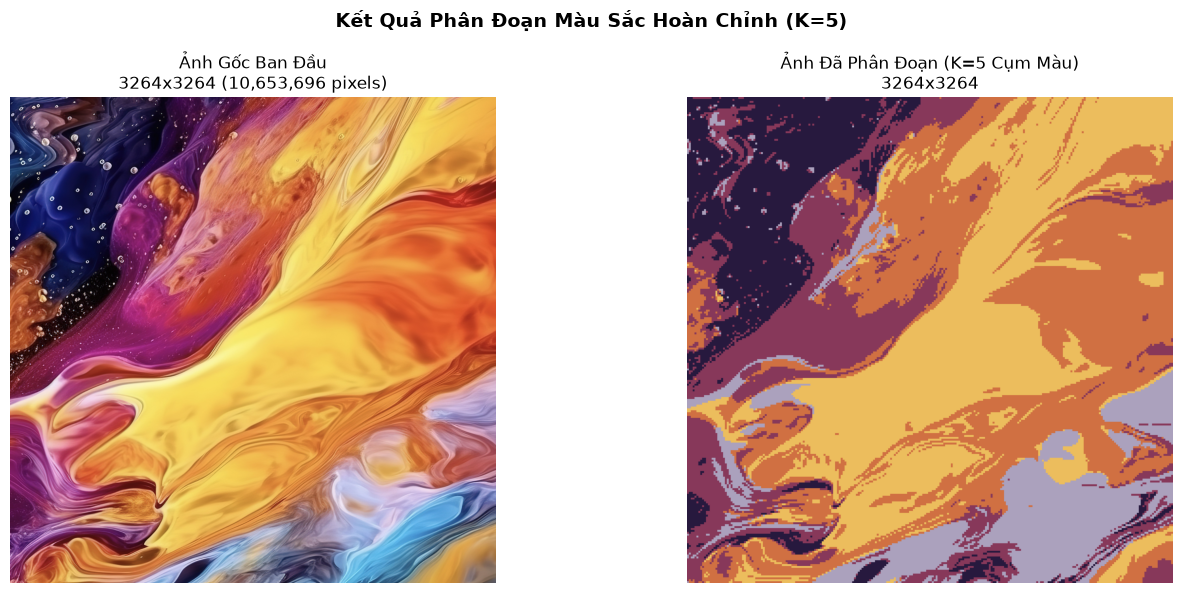

2026-11-14 11:10:08 [INFO] Visualization — Đã lưu cluster distribution: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\results\figures\cluster_distribution_nb03.png
=== BẢNG PHÂN BỔ TỶ LỆ DIỆN TÍCH CÁC CỤM MÀU ===


,cluster_id,color_name,centroid_rgb,pixel_count,share_percentage
0,0,Cam (Orange),"[209, 112, 67]",19915,30.39
1,2,Vàng (Yellow),"[237, 189, 93]",17837,27.22
2,1,Đỏ (Red),"[136, 57, 90]",11513,17.57
3,4,Đen (Black),"[40, 25, 62]",8489,12.95
4,3,Tím (Violet),"[172, 162, 190]",7782,11.87


In [5]:
# 1. Hiển thị song song ảnh gốc vs ảnh phân đoạn
plot_side_by_side(
    original_img=img_rgb,
    segmented_img=segmented_orig,
    k=optimal_k,
    title=f"So sánh Ảnh Gốc vs Ảnh Phân Đoạn K-Means (K={optimal_k})",
    save_path=FIGURES_DIR / "final_segmentation_side_by_side_nb03.png"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img_rgb)
axes[0].set_title(f"Ảnh Gốc Ban Đầu\n{orig_shape[0]}x{orig_shape[1]} ({metadata['total_pixels']:,} pixels)")
axes[0].axis("off")

axes[1].imshow(segmented_orig)
axes[1].set_title(f"Ảnh Đã Phân Đoạn (K={optimal_k} Cụm Màu)\n{orig_shape[0]}x{orig_shape[1]}")
axes[1].axis("off")

plt.suptitle(f"Kết Quả Phân Đoạn Màu Sắc Hoàn Chỉnh (K={optimal_k})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Thống kê và vẽ biểu đồ tỷ lệ diện tích các màu sắc
cluster_stats = extract_color_distribution(labels, centroids)
plot_cluster_distribution(cluster_stats, save_path=FIGURES_DIR / "cluster_distribution_nb03.png")

print("=== BẢNG PHÂN BỔ TỶ LỆ DIỆN TÍCH CÁC CỤM MÀU ===")
df_stats = pd.DataFrame(cluster_stats)
display(df_stats[["cluster_id", "color_name", "centroid_rgb", "pixel_count", "share_percentage"]])

### 6. Kết luận
- Phương pháp Elbow Method kết hợp Kneedle đã tự động xác định được số lượng cụm màu sắc đại diện hợp lý mà không cần gán cứng thủ công.
- Quá trình tái tạo ảnh và phục hồi kích thước gốc đã hoàn thành xuất sắc yêu cầu Task 4 và Task 5 của đề bài.